# 02 — Linear Regression with XinML

Predict a numerical measure of diabetes progression from baseline
measurements using our NumPy least-squares implementation. We evaluate
predictions on a held-out test set rather than on training data.

Dataset: [scikit-learn Diabetes](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_diabetes.html).
The target is a progression measure one year after baseline; features
include age, coded sex, BMI, blood pressure, and serum measurements.
No external data download is required.

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, r2_score
from xinml import LinearRegression

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False})
assert LinearRegression.__module__ == "xinml.linear_regression"

## 1. Load raw features and split the data

scaled=False avoids the loader's complete-dataset normalization.
We make a reproducible 80/20 split before computing preprocessing
statistics. All ten features are retained; the test set is not used
for feature selection or model fitting.

In [2]:
dataset = load_diabetes(as_frame=True, scaled=False)
X, y = dataset.data, dataset.target
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
assert set(X_train.index).isdisjoint(X_test.index)
display(pd.Series({
    "Total observations": len(X),
    "Features": X.shape[1],
    "Training observations": len(X_train),
    "Test observations": len(X_test),
}, name="Dataset and split").to_frame())

,Dataset and split
Total observations,442
Features,10
Training observations,353
Test observations,89


## 2. Explore the training data

Check missing values and summarize the training target. A BMI scatter
plot gives a simple view of one feature's relationship to progression;
the model itself will use all ten features.

Missing training values: 0


,Training target
count,353.00
mean,153.74
std,78.06
min,25.00
25%,86.00
50%,142.00
75%,214.00
max,346.00


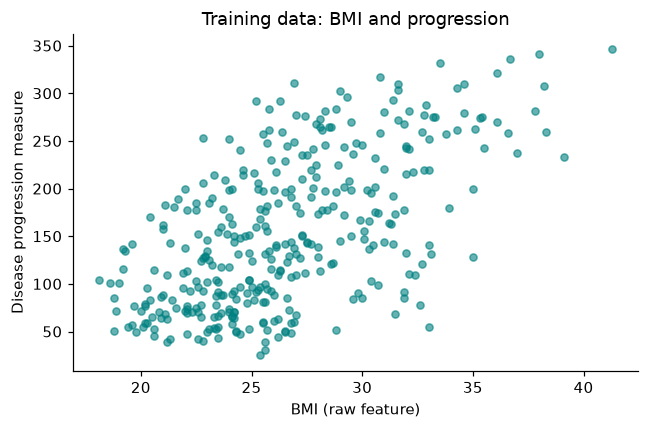

In [3]:
assert X_train.isna().sum().sum() == 0
assert y_train.isna().sum() == 0
print("Missing training values:", int(X_train.isna().sum().sum()))
display(y_train.describe().round(2).to_frame("Training target"))

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(X_train["bmi"], y_train, alpha=0.6, s=22, color="teal")
ax.set(title="Training data: BMI and progression",
       xlabel="BMI (raw feature)", ylabel="Disease progression measure")
fig.tight_layout()
plt.show()

## 3. Standardize using training data only

Least squares with an intercept does not require standardization,
but scaling makes differently sized feature columns easier to work
with and improves numerical conditioning. Fit the scaler only on
training rows and apply the same transformation to test rows.
Keep the target in its original units.

In [4]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
assert scaler.n_samples_seen_ == len(X_train)
np.testing.assert_allclose(scaler.mean_, X_train.mean().to_numpy())
np.testing.assert_allclose(X_train_scaled.mean(axis=0), 0.0, atol=1e-12)

## 4. Train the custom model and predict

XinML fits an intercept and coefficients by minimizing squared errors
with NumPy's least-squares solver. Scikit-learn is used for utilities,
not for the regression model.

In [5]:
model = LinearRegression(fit_intercept=True)
model.fit(X_train_scaled, y_train)
predictions = model.predict(X_test_scaled)
assert predictions.shape == y_test.shape
assert np.all(np.isfinite(predictions))
display(pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Predicted": predictions,
}).head().round(2))

,Actual,Predicted
0,219.0,139.55
1,70.0,179.52
2,202.0,134.04
3,230.0,291.42
4,111.0,123.79


## 5. Evaluate held-out predictions

R² compares squared prediction error with variation around the test
target mean. Higher is better, and negative scores are possible.
MSE is the mean squared error; RMSE is its square root, in the target's
original units. Lower MSE and RMSE are better.

In [6]:
r_squared = model.score(X_test_scaled, y_test)
mse = mean_squared_error(y_test, predictions)
rmse = float(np.sqrt(mse))
np.testing.assert_allclose(r_squared, r2_score(y_test, predictions))
np.testing.assert_allclose(rmse ** 2, mse)
assert np.all(np.isfinite([r_squared, mse, rmse]))
assert r_squared <= 1.0 and mse >= 0.0 and rmse >= 0.0
display(pd.Series({
    "R²": r_squared,
    "MSE": mse,
    "RMSE": rmse,
}, name="Test performance").round(4).to_frame())

,Test performance
R²,0.4526
MSE,2900.1936
RMSE,53.8534


## 6. Compare actual and predicted values

Points on the dashed line would be perfect predictions. Distance from
the line shows prediction error. This is a test-set plot, so it shows
performance on observations the model did not use during fitting.

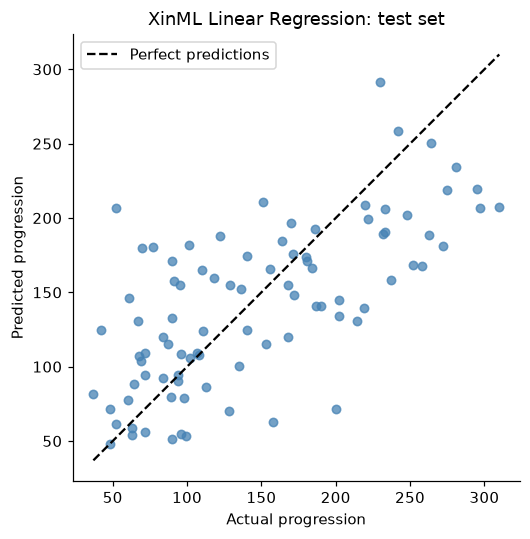

In [7]:
limits = [min(y_test.min(), predictions.min()),
          max(y_test.max(), predictions.max())]
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(y_test, predictions, alpha=0.75, s=30, color="steelblue")
ax.plot(limits, limits, "k--", label="Perfect predictions")
ax.set(title="XinML Linear Regression: test set",
       xlabel="Actual progression", ylabel="Predicted progression")
ax.set_aspect("equal", adjustable="box")
ax.legend()
fig.tight_layout()
plt.show()

## Conclusion

On the 89 held-out observations, XinML achieves R² = **0.4526**, MSE = **2900.1936**, and RMSE = **53.8534**. The model captures some variation, but the scatter around the diagonal shows substantial prediction error. RMSE is measured in the target's original units.

This linear model and one fixed split provide a simple baseline, not a guarantee of performance on every sample. The scaler and model were fitted only on training rows.